In [ ]:
## MODULE-5: LINEAR REGRESSION
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
## load data
df = pd.read_csv('QADSMLP-learner/data/housing_data.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20526 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   Target      20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
count,20640.000000,20640.000000,20526.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429918,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.479265,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440789,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229190,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [5]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [6]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
20635    False
20636    False
20637    False
20638    False
20639    False
Length: 20640, dtype: bool

In [7]:
df.duplicated().sum()

np.int64(0)

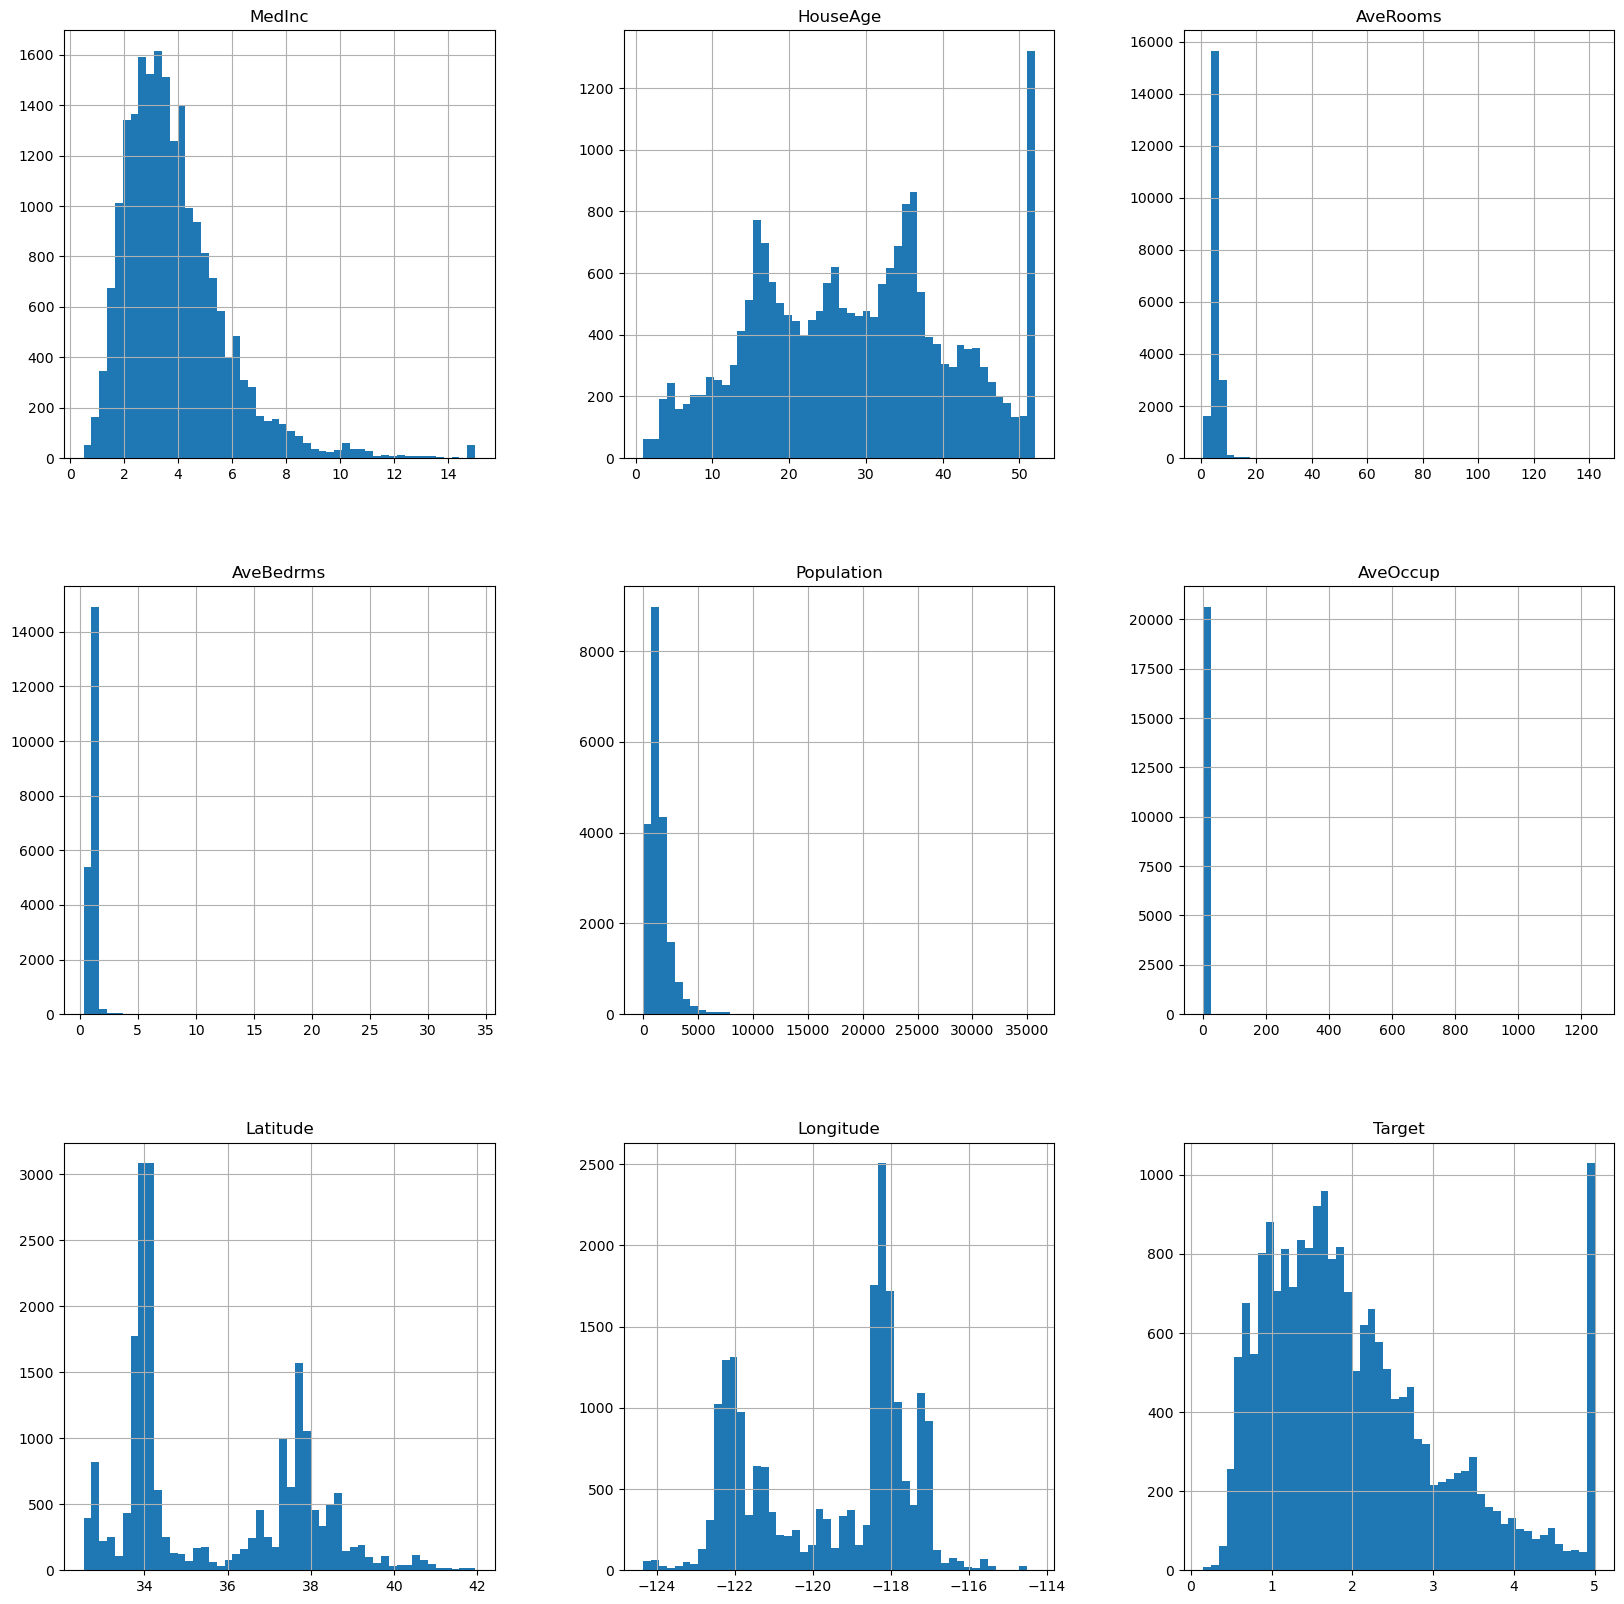

In [10]:
## visualising the distribution
df.hist(bins = 50, figsize=(20,20));

In [ ]:
## testing assumptions
## 1) Each variable is linearly correlated
## 2) No multi-collinearity - none of the features are highly correlated with others

## features = independent variables / predictors you use to predict the target (columns in df excluding the target).

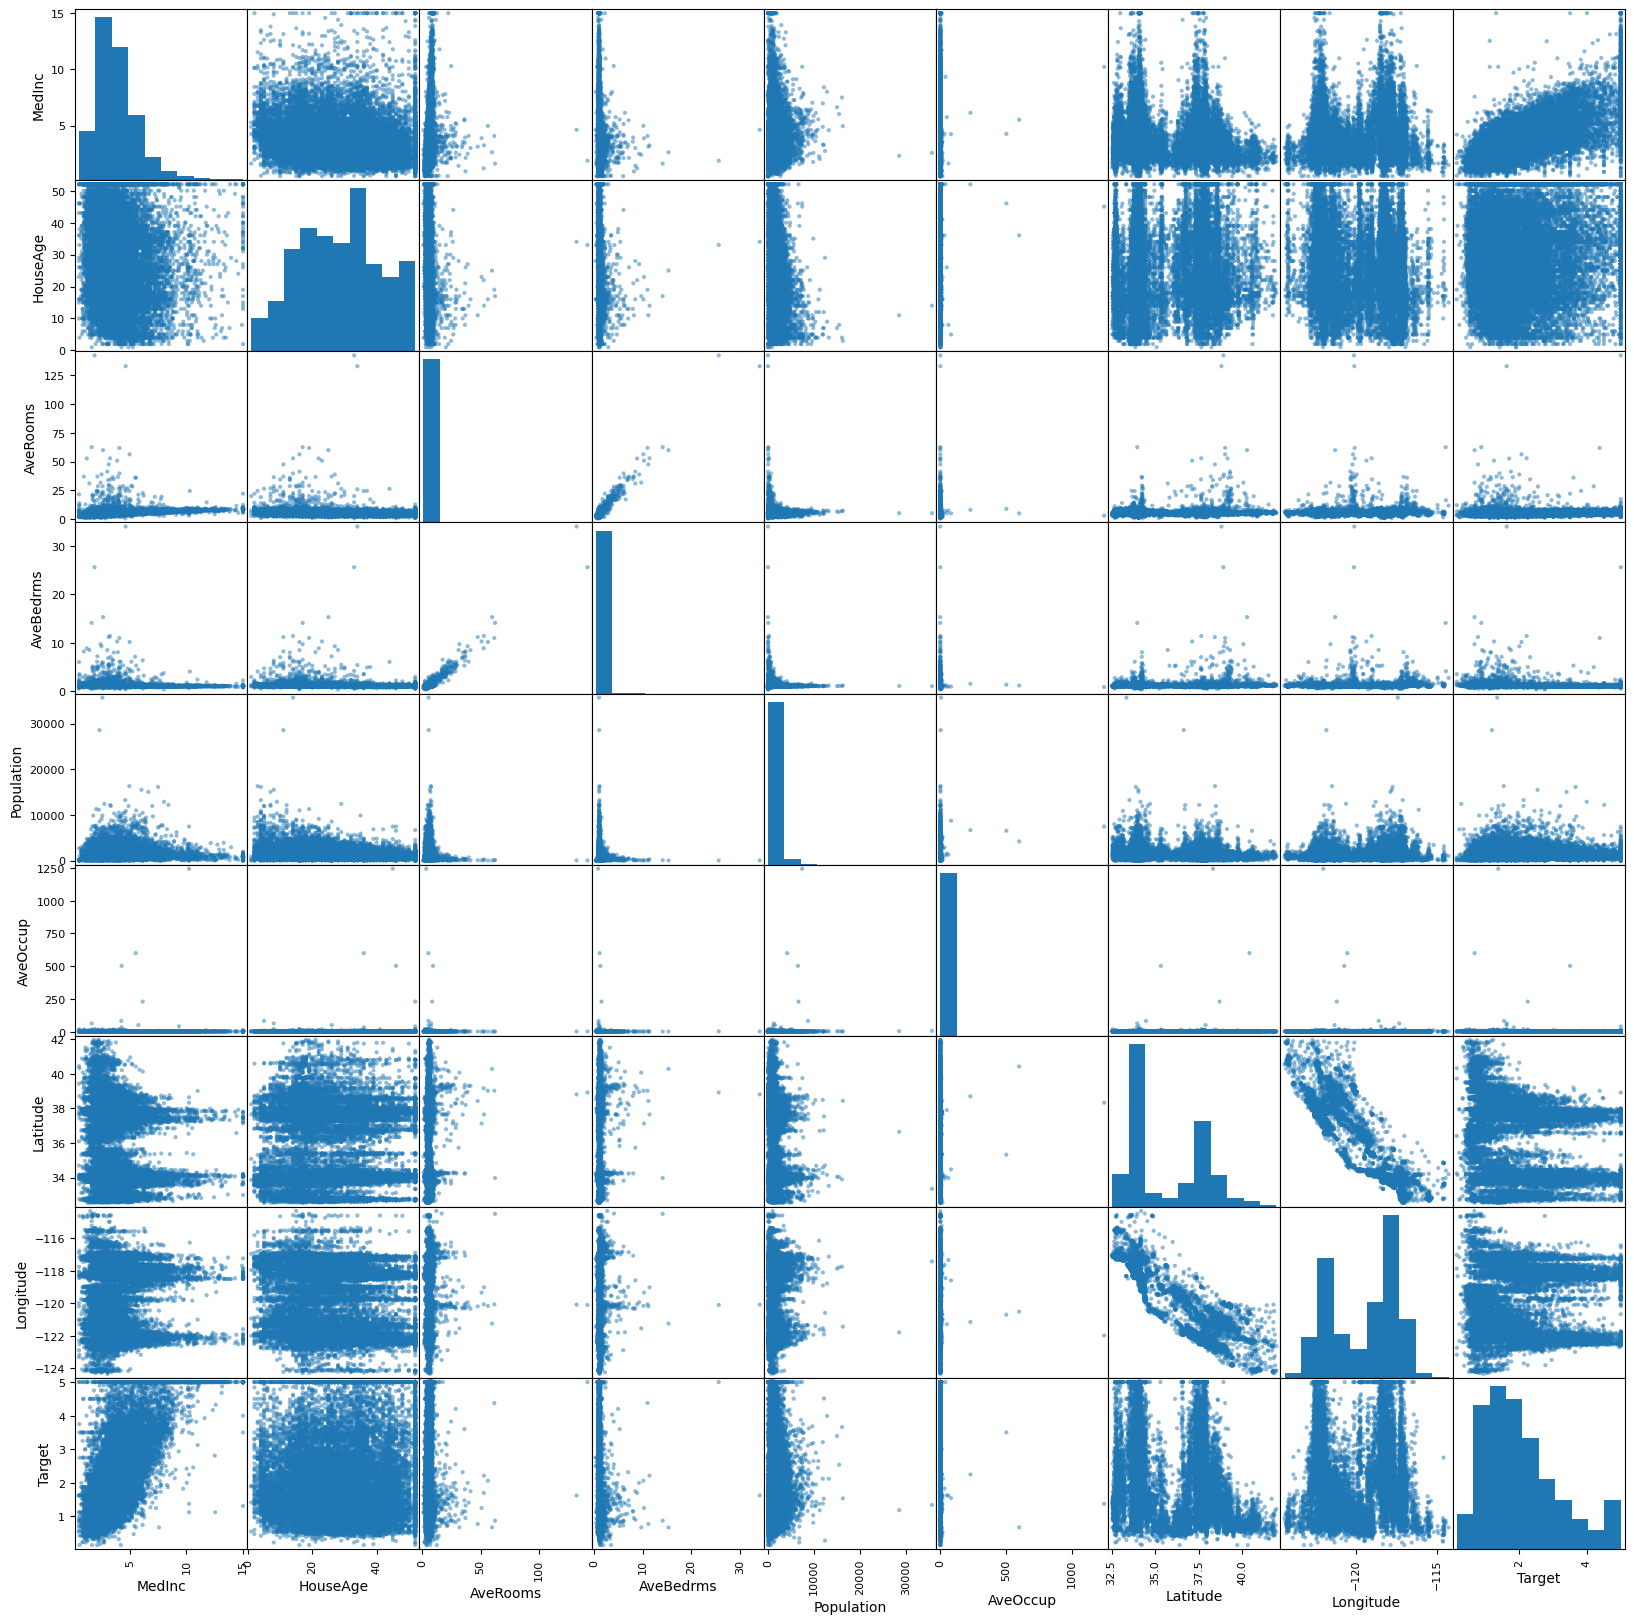

In [15]:
pd.plotting.scatter_matrix(df, figsize=(20,20));

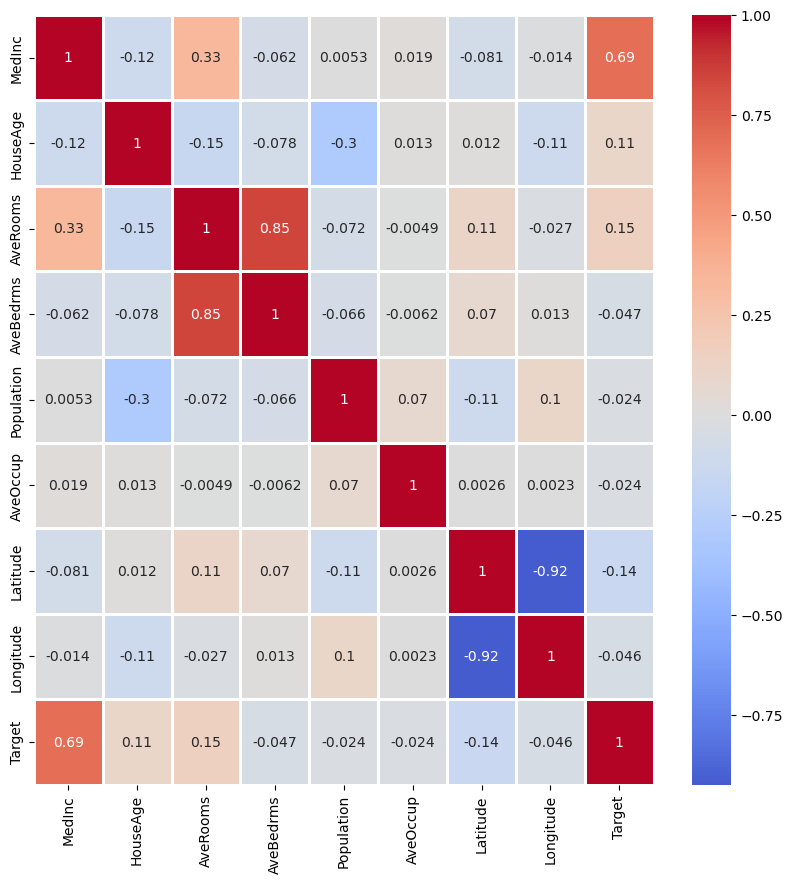

In [ ]:
## heatmap
# Creating an axes on which to draw the heatmap
fig, ax =  plt.subplots(figsize = (10,10))
# Plotting the heatmap on the axes
sns.heatmap(df.corr(method='pearson'), annot=True, linewidths=0.8, center=0.0, ax=ax, cmap = 'coolwarm');

##How to interpret values: |r| > 0.7 ≈ strong, 0.3–0.7 moderate, <0.3 weak. Sign indicates direction (positive/negative).
##High correlation between a feature and the target → good predictive signal.
##High correlation among features → multicollinearity risk (inflated variance of coefficients), may violate OLS assumptions.

In [ ]:
## drop rows
df = df.dropna().copy()

In [20]:
# Train test split
# Importing package
from sklearn.model_selection import train_test_split

In [ ]:
cols = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

In [26]:
#Splitting the data into test and train sets
X_train, X_test, y_train, y_test = train_test_split(df[cols],
                                                    df['Target'],
                                                    test_size=0.30,
                                                    random_state =42)

In [27]:
## scaling data = aid result interpretation
from sklearn.preprocessing import StandardScaler

# Calling the method twice, once for the features and once for the target
scaler =  StandardScaler()
scaler_target = StandardScaler()

In [ ]:
# Fitting the scaler on the training features and applying it to both the training and test data
# Note how the Scaler is only fit to the training set, but then applied to both
'''
scaler.fit_transform(X_train) — computes scaling parameters (e.g., mean and std for StandardScaler) from X_train and then transforms X_train using those parameters.
scaler.transform(X_test) — uses the already-computed parameters from the fitted scaler to transform X_test (no re-computation).
Fitting on train only prevents data leakage. 
If you call fit on test (or use fit_transform on test), the scaler learns information from the test set which can produce overly optimistic evaluation results.
'''
X_train[cols] = scaler.fit_transform(X_train.values)
X_test[cols] = scaler.transform(X_test.values)

In [29]:
# Fitting the scaler on the training target and applying it to both the training and test data
y_train = scaler_target.fit_transform(y_train.values.reshape(-1, 1))
y_test = scaler_target.transform(y_test.values.reshape(-1, 1))

In [33]:
print(y_train)
print(X_train[cols])


[[0.65509665]
 [0.7438245 ]
 [0.0235631 ]
 ...
 [1.45799673]
 [0.65944605]
 [0.42283844]]
         MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
10421  0.083774  0.193605 -0.136011   0.016526    0.447844 -0.051173   
9108   1.721358 -1.718118  0.843891  -0.182701   -0.392630 -0.010412   
1014   0.426018  0.990156 -0.092260  -0.126367   -0.704347 -0.076525   
8914  -0.393933  0.830846 -0.444032  -0.216246   -0.474802  0.004684   
2097  -1.403271  0.910501 -0.614122  -0.148929    0.715796  0.115283   
...         ...       ...       ...        ...         ...       ...   
11350 -0.542153 -0.204671 -0.334560  -0.106669   -0.674872  0.073893   
12033 -0.338008  0.432570 -0.062983  -0.088659    0.074499  0.063725   
5422   0.345478  1.229121 -0.591348  -0.553940   -0.974978 -0.084708   
862    1.230737  0.193605  0.213269  -0.239756   -0.126465 -0.037738   
15878 -0.680727  1.866362 -0.308658  -0.033640   -0.176483  0.030516   

       Latitude  Longitude    Target  
10421 

In [ ]:
## Building model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

In [54]:
## Create a LinearRegression model, setting fit_intercept=False. Then use the fit method to train the model on X_train and y_train. 
regressor = LinearRegression(fit_intercept = False)
# Fit the model
regressor.fit(X_train[cols].values,y_train)
 # Carry out predictions on our test set
y_pred = regressor.predict(X_test[cols])
y_pred


/opt/homebrew/Caskroom/miniconda/base/envs/dsml/lib/python3.11/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


array([[ 0.44510317],
       [-0.21277467],
       [-0.28493486],
       ...,
       [-0.42704661],
       [-1.13148643],
       [-0.45163104]], shape=(6158, 1))

In [55]:
## MedInc on X compared to target
cols = ['MedInc']

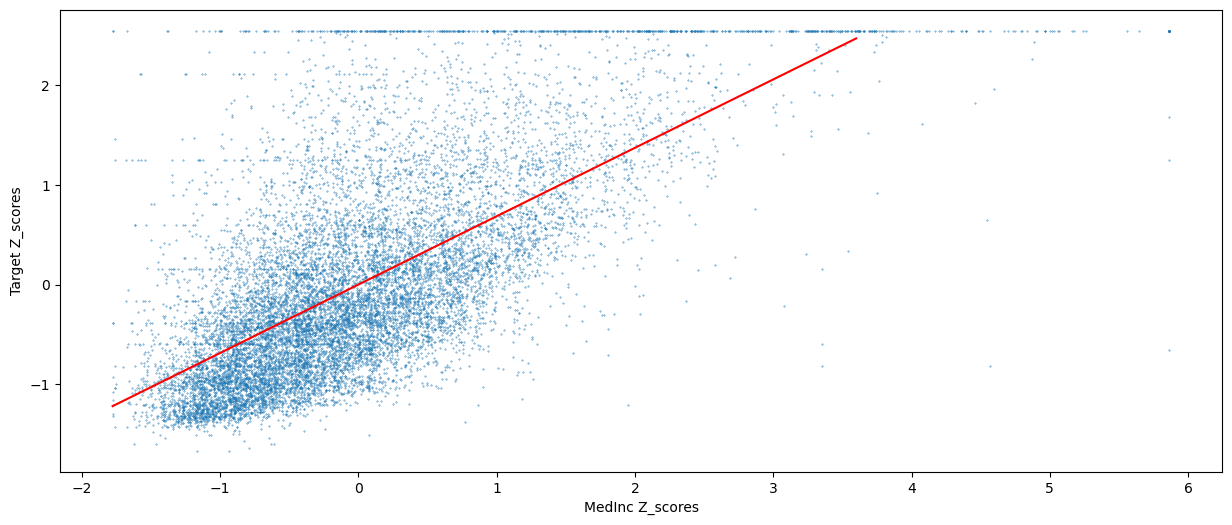

In [56]:
## plotting model
plt.figure(figsize=(15, 6))
# Plotting MedInc against the Target
plt.scatter(X_train[cols], y_train, s=0.1)
# Selecting x values to input into the model
# Started at the min value of MedInc that we have,
# the upper limit was found by experimenitng so as not to exceed the y value
# in this case the linear model is very poor at predicting anything over a standardised x value of over 3
x = np.linspace(X_train[cols].min(), 3.6, 100)
# Using the gradient and intercept from the model to plot
# The intercept is zero but it is added for completeness
# y = m *x+ c

y = (regressor.coef_)*x+(regressor.intercept_)
# # Plotting the linear model
plt.plot(x, y, '-r')
# # Adding labels to each axis
plt.xlabel('MedInc Z_scores')
plt.ylabel('Target Z_scores')
# calling the plot
plt.show()

In [ ]:
## Evaluating the model
 # first we need to reverse the transformation so we have meanginful results
y_true = scaler_target.inverse_transform(y_test) #<-- observed vals
y_pred = scaler_target.inverse_transform(y_pred) # <-- predicted vals

In [58]:
  # Calculating the errors
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)

In [59]:
# creating a dictionary to hold results
results = {}

# Calculting the R^2
r2 = r2_score(y_true, y_pred)

results[str(cols)] = {'RMSE':rmse,
                    'r^2': r2, 'MAE': mae, 'MSE': mse}

In [60]:
df_results = pd.DataFrame.from_dict(results, orient = 'index')

In [61]:
df_results

,RMSE,r^2,MAE,MSE
['MedInc'],0.842094,0.47819,0.630475,0.709122


In [ ]:
# Evaluating model performance
## RMSE: 0.842 — RMSE penalises large errors. Its higher than MAE but not noticeably
## R²: 0.478 — MedInc alone explains ~48% of the variance in house prices. That's a moderate relationship—decent but not strong.
## MAE: 0.630 — Average absolute error is 0.63 units. Predictions are off by 63k
## MSE: 0.709 — Mean squared error.

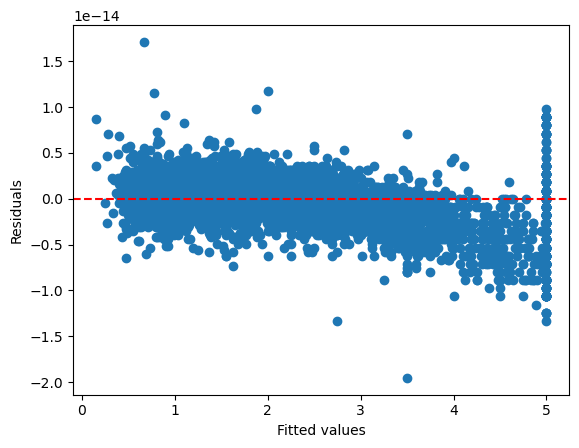

In [53]:
residuals = y_true - y_pred
plt.scatter(y_pred, residuals)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.show()